<a href="https://colab.research.google.com/github/Salalahmdi/Advanced-Statistics-Transportation/blob/main/Assignment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Distribution                                                    Parameters  LogLikelihood          AIC  KS_statistic     KS_pvalue
   Lognormal (0.1886881193912029, -13.691496032479744, 22.189361938575836)   -6842.140143 13690.280287      0.033975  7.664070e-03
      Normal                         (8.894666666666668, 4.25517389643348)   -6880.977991 13765.955983      0.060380  4.764382e-08
   Student t   (1799471727.3699963, 8.894654272085873, 4.2551609961051575)   -6880.977992 13767.955983      0.060380  4.765859e-08
     Uniform                                                   (1.0, 18.8)   -7041.256488 14086.512975      0.187589  2.050490e-74
 Exponential                                      (1.0, 7.894666666666668)   -7358.849822 14721.699645      0.231752 8.026648e-114
\nBest distribution: Lognormal
PDF at 15: 0.029148193451322836
P(X = 15): 0.0
P(X <= 15): 0.9133965186392528
85th percentile: 13.290657015099338


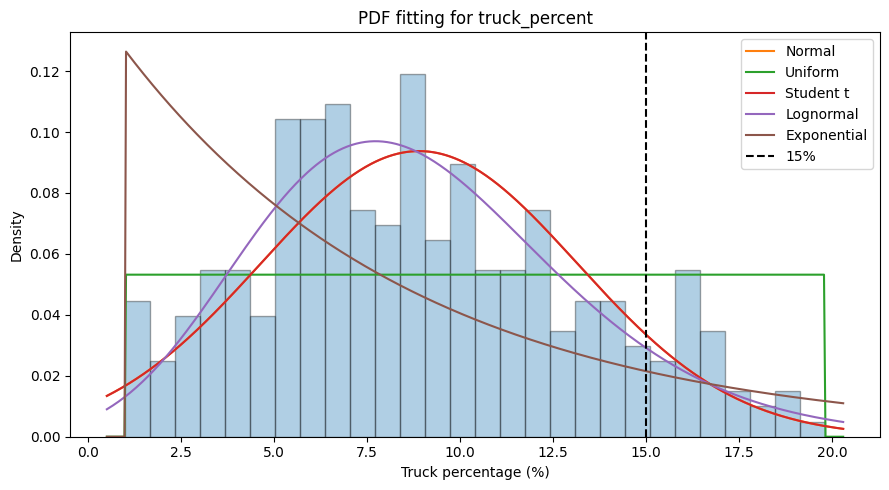

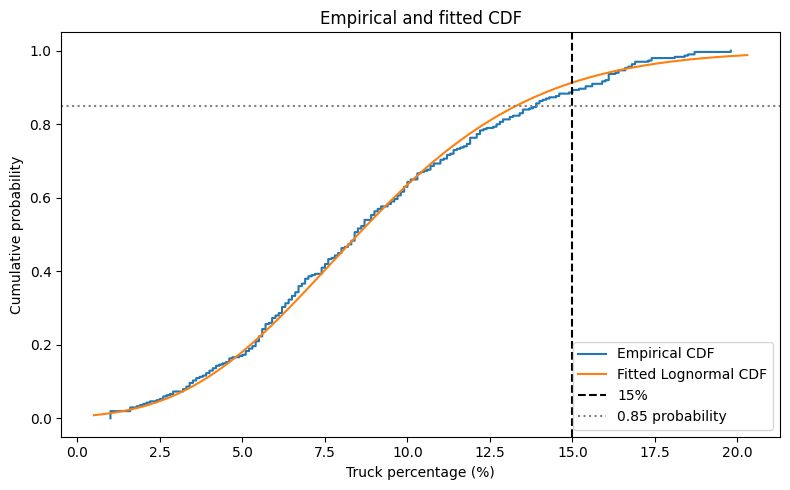

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("/content/pavement_transportation_master_dataset.csv")
x = df["truck_percent"].dropna().astype(float).to_numpy()

distributions = {
    "Normal": stats.norm,
    "Uniform": stats.uniform,
    "Student t": stats.t,
    "Lognormal": stats.lognorm,
    "Exponential": stats.expon
}

fits = {}
results = []

for name, distribution in distributions.items():
    params = distribution.fit(x)
    fits[name] = params

    log_likelihood = np.sum(distribution.logpdf(x, *params))
    k = len(params)
    aic = 2 * k - 2 * log_likelihood

    ks_stat, ks_p = stats.kstest(
        x, distribution.cdf, args=params
    )

    results.append({
        "Distribution": name,
        "Parameters": params,
        "LogLikelihood": log_likelihood,
        "AIC": aic,
        "KS_statistic": ks_stat,
        "KS_pvalue": ks_p
    })

results = pd.DataFrame(results).sort_values("AIC")
print(results.to_string(index=False))

best_name = results.iloc[0]["Distribution"]
best_dist = distributions[best_name]
best_params = fits[best_name]

pdf_15 = best_dist.pdf(15, *best_params)
prob_at_most_15 = best_dist.cdf(15, *best_params)
percent_at_85 = best_dist.ppf(0.85, *best_params)

print("\\nBest distribution:", best_name)
print("PDF at 15:", pdf_15)
print("P(X = 15):", 0.0)
print("P(X <= 15):", prob_at_most_15)
print("85th percentile:", percent_at_85)

grid = np.linspace(x.min() - 0.5, x.max() + 0.5, 500)

plt.figure(figsize=(9, 5))
plt.hist(x, bins=28, density=True, alpha=0.35, edgecolor="black")
for name, distribution in distributions.items():
    plt.plot(grid, distribution.pdf(grid, *fits[name]), label=name)
plt.axvline(15, color="black", linestyle="--", label="15%")
plt.xlabel("Truck percentage (%)")
plt.ylabel("Density")
plt.title("PDF fitting for truck_percent")
plt.legend()
plt.tight_layout()
plt.show()

sorted_x = np.sort(x)
ecdf = np.arange(1, len(x) + 1) / len(x)

plt.figure(figsize=(8, 5))
plt.step(sorted_x, ecdf, where="post", label="Empirical CDF")
plt.plot(grid, best_dist.cdf(grid, *best_params), label=f"Fitted {best_name} CDF")
plt.axvline(15, color="black", linestyle="--", label="15%")
plt.axhline(0.85, color="gray", linestyle=":", label="0.85 probability")
plt.xlabel("Truck percentage (%)")
plt.ylabel("Cumulative probability")
plt.title("Empirical and fitted CDF")
plt.legend()
plt.tight_layout()
plt.show()
